In [2]:
# pip install duckdb
# import duckdb

In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

pd.set_option('display.max_columns',None)

def display_():
    plt.tight_layout()
    plt.show()

DATA_DIR = Path("data")
REVIEWS_CSV = DATA_DIR / "combined_reviews.csv"

df_OG = pd.read_csv(REVIEWS_CSV)

# Cleaning

In [4]:
df_OG['date'] = pd.to_datetime(df_OG['date'], format='%Y-%m-%d')
df_filtered = df_OG[(df_OG['verified'] == "Trip Verified")\
    & (df_OG['content'].str.startswith("✅ Trip Verified | "))]\
    .drop(['author','verified'],axis=1)
df = df_filtered.copy()
df['content'] = df_filtered['content'].str[18:]
display(df.columns)
display(df.info())
display(df.head())
display(df['date'].describe())


Index(['airline', 'overall_rating', 'title', 'author_country', 'date',
       'content', 'type_of_traveller', 'cabin_flown', 'route', 'date_flown',
       'seat_comfort', 'cabin_staff_service', 'food_and_beverages',
       'inflight_entertainment', 'ground_service', 'wifi_and_connectivity',
       'value_for_money', 'recommended'],
      dtype='object')

<class 'pandas.core.frame.DataFrame'>
Index: 12463 entries, 1 to 28822
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   airline                 12463 non-null  object        
 1   overall_rating          12463 non-null  float64       
 2   title                   12463 non-null  object        
 3   author_country          12463 non-null  object        
 4   date                    12463 non-null  datetime64[ns]
 5   content                 12463 non-null  object        
 6   type_of_traveller       12463 non-null  object        
 7   cabin_flown             12463 non-null  object        
 8   route                   12437 non-null  object        
 9   date_flown              12463 non-null  object        
 10  seat_comfort            11684 non-null  float64       
 11  cabin_staff_service     11622 non-null  float64       
 12  food_and_beverages      7820 non-null   float64    

None

,airline,overall_rating,title,author_country,date,content,type_of_traveller,cabin_flown,route,date_flown,seat_comfort,cabin_staff_service,food_and_beverages,inflight_entertainment,ground_service,wifi_and_connectivity,value_for_money,recommended
1,American Airlines,2.0,customer support is poor,United States,2026-05-19,On 5.13.2026 I lost my second flight to Iowa...,Solo Leisure,Economy Class,Rochester to Des Moines via Washington,May 2026,2.0,4.0,2.0,NaN,2.0,NaN,2.0,0
2,American Airlines,1.0,never fly with American Airlines again,United States,2026-05-15,I had an extremely disappointing experience ...,Family Leisure,Economy Class,La Guardia to Chicago,April 2026,1.0,1.0,NaN,NaN,1.0,NaN,1.0,0
4,American Airlines,10.0,crew on this flight was fantastic,United States,2026-05-11,This was my first intercontinental flight wi...,Solo Leisure,Economy Class,Buenos Aires to New York JFK,May 2026,4.0,5.0,5.0,4.0,5.0,1.0,5.0,1
8,American Airlines,8.0,“worst meal ever served to me”,United Kingdom,2026-04-21,The flight was only delayed 20 minutes due l...,Couple Leisure,Economy Class,London to Philadelphia,April 2026,4.0,4.0,1.0,3.0,4.0,NaN,4.0,1
10,American Airlines,2.0,Total and utter indifference,United States,2026-04-12,What a disappointment. So I made the switch ...,Business,Economy Class,London to Miami,April 2026,2.0,1.0,1.0,2.0,2.0,2.0,1.0,0


count                            12463
mean     2021-01-03 19:58:10.235096064
min                2017-11-18 00:00:00
25%                2019-01-04 00:00:00
50%                2021-02-17 00:00:00
75%                2022-10-04 00:00:00
max                2026-06-04 00:00:00
Name: date, dtype: object

EDA Notes:
~10% of reviews are from non-american authors (author_country != USA)

In [5]:
df.shape
df['date'] = pd.to_datetime(df['date'], format='%Y-%m-%d')
display(df['airline'].value_counts())
display(df.info())
display(df.describe().T)


airline
American Airlines     2876
United Airlines       2202
Spirit Airlines       2046
Frontier Airlines     1865
Delta Air Lines       1378
Southwest Airlines     742
JetBlue Airways        730
Alaska Airlines        443
Hawaiian Airlines      181
Name: count, dtype: int64

<class 'pandas.core.frame.DataFrame'>
Index: 12463 entries, 1 to 28822
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   airline                 12463 non-null  object        
 1   overall_rating          12463 non-null  float64       
 2   title                   12463 non-null  object        
 3   author_country          12463 non-null  object        
 4   date                    12463 non-null  datetime64[ns]
 5   content                 12463 non-null  object        
 6   type_of_traveller       12463 non-null  object        
 7   cabin_flown             12463 non-null  object        
 8   route                   12437 non-null  object        
 9   date_flown              12463 non-null  object        
 10  seat_comfort            11684 non-null  float64       
 11  cabin_staff_service     11622 non-null  float64       
 12  food_and_beverages      7820 non-null   float64    

None

,count,mean,min,25%,50%,75%,max,std
overall_rating,12463.0,2.328894,1.0,1.0,1.0,2.0,10.0,2.641545
date,12463,2021-01-03 19:58:10.235096064,2017-11-18 00:00:00,2019-01-04 00:00:00,2021-02-17 00:00:00,2022-10-04 00:00:00,2026-06-04 00:00:00,NaN
seat_comfort,11684.0,1.965252,1.0,1.0,1.0,3.0,5.0,1.281953
cabin_staff_service,11622.0,2.225779,1.0,1.0,2.0,3.0,5.0,1.464421
food_and_beverages,7820.0,1.918414,1.0,1.0,1.0,3.0,5.0,1.309695
inflight_entertainment,6851.0,2.013137,1.0,1.0,1.0,3.0,5.0,1.428225
ground_service,12135.0,1.730696,1.0,1.0,1.0,2.0,5.0,1.323605
wifi_and_connectivity,6386.0,1.766207,1.0,1.0,1.0,2.0,5.0,1.305728
value_for_money,12463.0,1.694375,1.0,1.0,1.0,2.0,5.0,1.263631
recommended,12463.0,0.133997,0.0,0.0,0.0,0.0,1.0,0.340662


In [6]:
df.groupby('airline')[['date','overall_rating']].describe()

date                                                      \
                   count                           mean                  min   
airline                                                                        
Alaska Airlines      443  2020-11-07 17:26:40.902934784  2017-11-21 00:00:00   
American Airlines   2876  2020-12-01 14:57:14.770514432  2017-11-18 00:00:00   
Delta Air Lines     1378  2021-02-06 00:14:37.793904128  2017-11-18 00:00:00   
Frontier Airlines   1865  2021-04-17 10:14:36.353887488  2017-11-20 00:00:00   
Hawaiian Airlines    181  2021-05-19 01:03:38.784530432  2017-11-20 00:00:00   
JetBlue Airways      730  2021-05-24 07:59:20.547945216  2017-11-19 00:00:00   
Southwest Airlines   742  2020-12-31 20:32:20.700808704  2017-11-21 00:00:00   
Spirit Airlines     2046  2020-11-20 06:01:45.571847424  2017-11-21 00:00:00   
United Airlines     2202  2020-10-26 22:10:47.411443968  2017-11-19 00:00:00   

                                                              \
                                    25%                  50%   
airline                                                        
Alaska Airlines     2019-01-24 12:00:00  2020-03-07 00:00:00   
American Airlines   2019-01-19 00:00:00  2020-08-03 12:00:00   
Delta Air Lines     2019-02-08 06:00:00  2021-05-25 12:00:00   
Frontier Airlines   2018-10-27 00:00:00  2022-02-17 00:00:00   
Hawaiian Airlines   2019-01-26 00:00:00  2022-01-11 00:00:00   
JetBlue Airways     2019-07-31 06:00:00  2021-09-06 12:00:00   
Southwest Airlines  2019-02-04 12:00:00  2021-02-18 12:00:00   
Spirit Airlines     2019-01-08 06:00:00  2021-01-12 00:00:00   
United Airlines     2018-11-15 12:00:00  2020-01-09 12:00:00   

                                                                   \
                                    75%                  max  std   
airline                                                             
Alaska Airlines     2022-05-10 00:00:00  2026-05-19 00:00:00  NaN   
American Airlines   2022-06-26 06:00:00  2026-05-19 00:00:00  NaN   
Delta Air Lines     2022-10-06 06:00:00  2026-05-30 00:00:00  NaN   
Frontier Airlines   2023-03-07 00:00:00  2026-06-02 00:00:00  NaN   
Hawaiian Airlines   2023-05-06 00:00:00  2026-05-15 00:00:00  NaN   
JetBlue Airways     2022-09-22 06:00:00  2026-04-17 00:00:00  NaN   
Southwest Airlines  2022-07-28 18:00:00  2026-06-04 00:00:00  NaN   
Spirit Airlines     2022-08-17 00:00:00  2026-03-30 00:00:00  NaN   
United Airlines     2022-08-09 06:00:00  2026-06-04 00:00:00  NaN   

                   overall_rating                                      \
                            count      mean  min  25%  50%  75%   max   
airline                                                                 
Alaska Airlines             443.0  3.101580  1.0  1.0  1.0  4.0  10.0   
American Airlines          2876.0  2.158554  1.0  1.0  1.0  2.0  10.0   
Delta Air Lines            1378.0  3.193759  1.0  1.0  1.0  5.0  10.0   
Frontier Airlines          1865.0  1.494370  1.0  1.0  1.0  1.0  10.0   
Hawaiian Airlines           181.0  3.359116  1.0  1.0  2.0  5.0  10.0   
JetBlue Airways             730.0  2.423288  1.0  1.0  1.0  2.0  10.0   
Southwest Airlines          742.0  3.173854  1.0  1.0  1.0  4.0  10.0   
Spirit Airlines            2046.0  1.863636  1.0  1.0  1.0  1.0  10.0   
United Airlines            2202.0  2.593097  1.0  1.0  1.0  3.0  10.0   

                              
                         std  
airline                       
Alaska Airlines     3.148809  
American Airlines   2.410535  
Delta Air Lines     3.172969  
Frontier Airlines   1.665767  
Hawaiian Airlines   2.953019  
JetBlue Airways     2.640874  
Southwest Airlines  3.190863  
Spirit Airlines     2.319994  
United Airlines     2.829825

<Axes: xlabel='overall_rating', ylabel='count'>

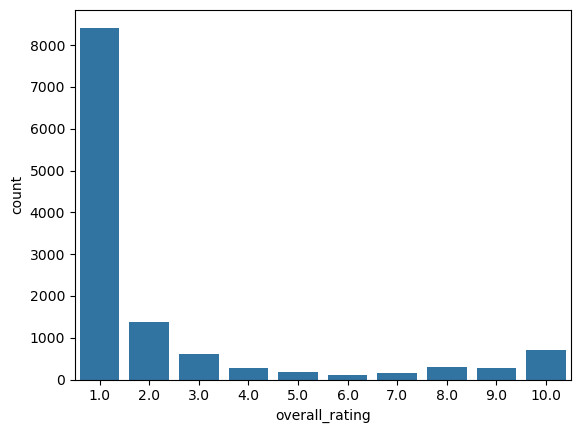

In [7]:
sns.barplot(df['overall_rating'].value_counts())

# Export

In [8]:
df.to_parquet('data/01_reviews_df.parquet')

------------------------